# Практическое занятие № 20. Полносвязная нейросеть в PyTorch
**ТюмГУ · «Технологии искусственного интеллекта — 1» · 90 минут**  
Автор учебных материалов: В. А. Мазур, доцент ШКН ТюмГУ.

**Результат:** собрать MLP, обучить её на прогнозе задержки доставки, использовать `autograd`, `DataLoader`, `BCEWithLogitsLoss` и Adam; контролировать обобщающую способность и сравнить с DummyClassifier и LogisticRegression на том же разбиении.

Если рядом есть `orders_dirty.csv`, будет выбран он; иначе — `demo_orders_19_20.csv` (отдельные синтетические данные). В Colab загрузите CSV во Files. У учебного набора не следует трактовать показатели как производственные результаты.

## 1. Настройка, проверка тензоров и autograd (0–18 мин)
Полносвязный нейрон: \(z=Wx+b\). `nn.BCEWithLogitsLoss()` объединяет sigmoid с логарифмической функцией потерь численно устойчивым способом; **не добавляйте `Sigmoid()` в конец модели**, если используете эту функцию. Студент должен прокомментировать, почему `loss.backward()` вычисляет градиенты по всей вычислительной схеме.

In [1]:
from pathlib import Path
from copy import deepcopy
import time, json
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display,Image
import torch,sklearn,joblib
from torch import nn
from torch.utils.data import TensorDataset,DataLoader
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,f1_score,average_precision_score,confusion_matrix,log_loss
SEED=42; STUDENT='Сидоров'; GROUP='нет'
np.random.seed(SEED);torch.manual_seed(SEED)
torch.set_num_threads(2)
device=torch.device('cpu')
print('Студент:',STUDENT,'группа:',GROUP,'seed:',SEED)
print('torch:',torch.__version__,'NumPy:',np.__version__,'pandas:',pd.__version__,'sklearn:',sklearn.__version__,'device:',device)

Студент: Сидоров группа: нет seed: 42
torch: 2.15.0+cpu NumPy: 2.3.5 pandas: 3.0.1 sklearn: 1.9.1 device: cpu


In [2]:
x=torch.tensor([[2.0,1.0]],requires_grad=True)
w=torch.tensor([[0.4],[-0.2]],requires_grad=True)
b=torch.tensor([-0.1],requires_grad=True)
z=x@w+b
z.sum().backward()
print('z:',z.item(),'dz/dx:',x.grad.numpy().tolist(),'dz/dw:',w.grad.numpy().tolist(),'dz/db:',b.grad.numpy().tolist())
assert torch.allclose(w.grad,x.T) and torch.allclose(x.grad,w.T)
assert torch.allclose(b.grad,torch.ones_like(b)) and torch.allclose(z,torch.tensor([[0.5]]))
print('Проверка: ∂z/∂w=x, поскольку z=Σxᵢwᵢ+b; autograd применил цепное правило к графу операций.')

z: 0.5 dz/dx: [[0.4000000059604645, -0.20000000298023224]] dz/dw: [[2.0], [1.0]] dz/db: [1.0]
Проверка: ∂z/∂w=x, поскольку z=Σxᵢwᵢ+b; autograd применил цепное правило к графу операций.


## 2. Аудит и разделение по времени (18–29 мин)
Единица наблюдения — заказ; метка \(y=late\) появляется после доставки. Для прогноза при оформлении допустимы только известные поля: расстояние, очередь, обещанный срок, загрузка курьера (если известна), погода, зона и час создания. `actual_minutes` используют только для проверки исторической метки. Разделение по времени: 60% train / 20% validation / 20% test. Проверки корректности **до** обучения.

In [3]:
dataset=Path('orders_dirty.csv')
assert dataset.exists(),'Для основного эксперимента требуется orders_dirty.csv'
raw=pd.read_csv(dataset,encoding='utf-8-sig')
required={'order_id','created_at','distance_km','queue_size','zone','weather','promised_minutes','actual_minutes','late'}
assert required<=set(raw.columns),f'Нет столбцов: {required-set(raw.columns)}'
audit=[]
for _,r in raw[raw.duplicated()].iterrows():audit.append((r.order_id,'полный дубль','исключён'))
df=raw.drop_duplicates().copy()
distance=df.distance_km.astype('string')
for oid in df.loc[distance.str.contains(',',regex=False,na=False),'order_id']:
    audit.append((oid,'десятичная запятая distance_km','заменена точкой'))
df['distance_km']=pd.to_numeric(distance.str.replace(',','.',regex=False),errors='coerce')
for col in ['queue_size','promised_minutes','actual_minutes','late']:
    df[col]=pd.to_numeric(df[col],errors='coerce')
for col in ['distance_km','queue_size','promised_minutes']:
    bad=df[col].isna() | (df[col]<0)
    for oid in df.loc[bad,'order_id']:
        audit.append((oid,f'пропуск, нечисловое или отрицательное {col}','импутация по train'))
    df.loc[df[col]<0,col]=np.nan
df['created_at']=pd.to_datetime(df.created_at,errors='coerce')
invalid=df.created_at.isna()|df.late.isna()|~df.late.isin([0,1])|df.order_id.isna()
for oid in df.loc[invalid,'order_id']:audit.append((oid,'дата, ID или метка некорректны','исключён'))
df=df.loc[~invalid].copy()
can_check=df.actual_minutes.notna()&df.promised_minutes.notna()
conflict=can_check & df.late.ne(((df.actual_minutes-df.promised_minutes)>15).astype(int))
for oid in df.loc[conflict,'order_id']:audit.append((oid,'late противоречит порогу 15 минут','исключён'))
df=df.loc[~conflict].copy()
assert df.order_id.is_unique,'Остались неоднозначные ID'
df['order_hour']=df.created_at.dt.hour.astype(float)
df=df.sort_values(['created_at','order_id'],kind='stable').reset_index(drop=True)
num_cols=['distance_km','queue_size','promised_minutes','order_hour']
if 'courier_load' in df.columns:
    df['courier_load']=pd.to_numeric(df.courier_load,errors='coerce')
    num_cols.append('courier_load')
cat_cols=['zone','weather']
assert not set(num_cols+cat_cols)&{'actual_minutes','late','order_id','created_at'}
nrows=len(df);ntrain=int(.6*nrows);nval=int(.2*nrows)
tr=df.iloc[:ntrain].copy();va=df.iloc[ntrain:ntrain+nval].copy();te=df.iloc[ntrain+nval:].copy()
assert len(tr)>20 and len(va)>6 and len(te)>6
assert set(tr.order_id).isdisjoint(va.order_id) and set(tr.order_id).isdisjoint(te.order_id) and set(va.order_id).isdisjoint(te.order_id)
assert tr.created_at.max()<=va.created_at.min() and va.created_at.max()<=te.created_at.min()
audit_table=pd.DataFrame(audit,columns=['order_id','причина','после'])
def original_value(row):
    oid=row['order_id'];issue=row['причина'];before=raw.loc[raw.order_id.eq(oid)].iloc[0]
    if issue=='полный дубль':return '2 одинаковые строки'
    if 'distance_km' in issue:return repr(before.distance_km)
    if 'queue_size' in issue:return 'пропуск' if pd.isna(before.queue_size) else repr(before.queue_size)
    if 'promised_minutes' in issue:return repr(before.promised_minutes)
    if 'late' in issue:return 'late='+str(before.late)
    return 'исходная запись'
audit_table.insert(1,'до',audit_table.apply(original_value,axis=1))
audit_table.loc[audit_table.причина.eq('полный дубль'),'после']='1 строка'
audit_table.loc[audit_table.причина.eq('десятичная запятая distance_km'),'после']='12.5'
audit_table.loc[audit_table.причина.str.contains('пропуск, нечисловое'),'после']='NaN → медиана train'
audit_table=audit_table[['order_id','до','после','причина']]
display(audit_table)
split_table=pd.DataFrame({'часть':['train','validation','test'],'N':[len(tr),len(va),len(te)],
 'начало':[tr.created_at.min(),va.created_at.min(),te.created_at.min()],
 'конец':[tr.created_at.max(),va.created_at.max(),te.created_at.max()]})
display(split_table)
print('Источник:',dataset.name,'исходно:',raw.shape,'после аудита:',df.shape)
print('Полные дубли:',int(raw.duplicated().sum()),'конфликтные метки:',int(conflict.sum()))
print('X:',num_cols+cat_cols,'y: late; courier_load отсутствует в источнике и не используется')
print('Test отложен до окончательной фиксации протокола; исходный CSV не изменён.')

,order_id,до,после,причина
0,ORD-0020,2 одинаковые строки,1 строка,полный дубль
1,ORD-0010,"'12,5'",12.5,десятичная запятая distance_km
2,ORD-0024,'unknown',NaN → медиана train,"пропуск, нечисловое или отрицательное distance_km"
3,ORD-0045,пропуск,NaN → медиана train,"пропуск, нечисловое или отрицательное queue_size"
4,ORD-0035,late=1,исключён,late противоречит порогу 15 минут


,часть,N,начало,конец
0,train,358,2026-08-25 08:00:00,2026-09-28 02:45:00
1,validation,119,2026-09-28 03:36:00,2026-10-06 00:45:00
2,test,121,2026-10-06 02:42:00,2026-10-15 05:06:00


Источник: orders_dirty.csv исходно: (600, 10) после аудита: (598, 11)
Полные дубли: 1 конфликтные метки: 1
X: ['distance_km', 'queue_size', 'promised_minutes', 'order_hour', 'zone', 'weather'] y: late; courier_load отсутствует в источнике и не используется
Test отложен до окончательной фиксации протокола; исходный CSV не изменён.


## 3. Безопасная предобработка (29–39 мин)
`ColumnTransformer`: для числовых полей медиана и стандартизация; для категорий мода и one-hot. **Обучаем `fit` только на train.** В PyTorch преобразуем результат в `torch.float32`. Списки признаков зафиксированы до просмотра test.

In [4]:
enc=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
prep=ColumnTransformer([
 ('num',Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())]),num_cols),
 ('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',enc)]),cat_cols)],remainder='drop')
Xtr=np.asarray(prep.fit_transform(tr[num_cols+cat_cols]),dtype=np.float32)
Xva=np.asarray(prep.transform(va[num_cols+cat_cols]),dtype=np.float32)
ytr=tr.late.to_numpy(dtype=np.float32).reshape(-1,1)
yva=va.late.to_numpy(dtype=np.float32).reshape(-1,1)
assert Xtr.dtype==Xva.dtype==np.float32 and np.isfinite(Xtr).all() and np.isfinite(Xva).all()
assert set(np.unique(ytr.ravel()))=={0,1}
feature_names=prep.get_feature_names_out()
print('X train/validation:',Xtr.shape,Xva.shape,'dtype:',Xtr.dtype)
print('Число входов после one-hot:',len(feature_names),'=',len(num_cols),'+',len(feature_names)-len(num_cols))
print('Имена признаков:',feature_names.tolist())
print('fit только train; validation только transform; test пока не преобразован')
train_loader=DataLoader(TensorDataset(torch.from_numpy(Xtr),torch.from_numpy(ytr)),batch_size=32,shuffle=True,generator=torch.Generator().manual_seed(SEED))
valid_loader=DataLoader(TensorDataset(torch.from_numpy(Xva),torch.from_numpy(yva)),batch_size=128,shuffle=False)

X train/validation: (358, 11) (119, 11) dtype: float32
Число входов после one-hot: 11 = 4 + 7
Имена признаков: ['num__distance_km', 'num__queue_size', 'num__promised_minutes', 'num__order_hour', 'cat__zone_center', 'cat__zone_east', 'cat__zone_north', 'cat__zone_south', 'cat__weather_clear', 'cat__weather_rain', 'cat__weather_snow']
fit только train; validation только transform; test пока не преобразован


## 4. Модель, функция потерь и оптимизатор (39–51 мин)
MLP: \(d_{in}\rightarrow 32\rightarrow 16\rightarrow 1\) с ReLU. Выход — **логит**, не вероятность. Параметры обучаются методом `Adam`. Количество параметров для Linear: \(d_{in}\cdot d_{out}+d_{out}\).

In [5]:
class DeliveryMLP(nn.Module):
    def __init__(self,n_inputs,hidden=(32,16)):
        super().__init__()
        layers=[];d=n_inputs
        for width in hidden:
            layers.extend([nn.Linear(d,width),nn.ReLU()]);d=width
        layers.append(nn.Linear(d,1))
        self.network=nn.Sequential(*layers)
    def forward(self,x):return self.network(x)
model=DeliveryMLP(Xtr.shape[1],(32,16)).to(device)
criterion=nn.BCEWithLogitsLoss()
optimizer=torch.optim.Adam(model.parameters(),lr=.001)
expected_params=(Xtr.shape[1]+1)*32+(32+1)*16+(16+1)
actual_params=sum(q.numel() for q in model.parameters())
print(model);print('Параметры по формуле:',expected_params,'по коду:',actual_params)
assert actual_params==expected_params
assert not isinstance(model.network[-1],nn.Sigmoid)

DeliveryMLP(
  (network): Sequential(
    (0): Linear(in_features=11, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)
Параметры по формуле: 929 по коду: 929


## 5. Mini-batch обучение, валидация и ранняя остановка (51–69 мин)
Цикл по пакетам: `zero_grad → forward → loss → backward → step`. Для validation: `model.eval()` и `torch.no_grad()`. Лучшее состояние сохраняется **по validation loss**, test в этом блоке недоступен. Для ускорения практикума всё работает на CPU.

Эпох: 38 лучшая эпоха: 26 validation BCE: 0.6027089953422546 время, с: 0.27


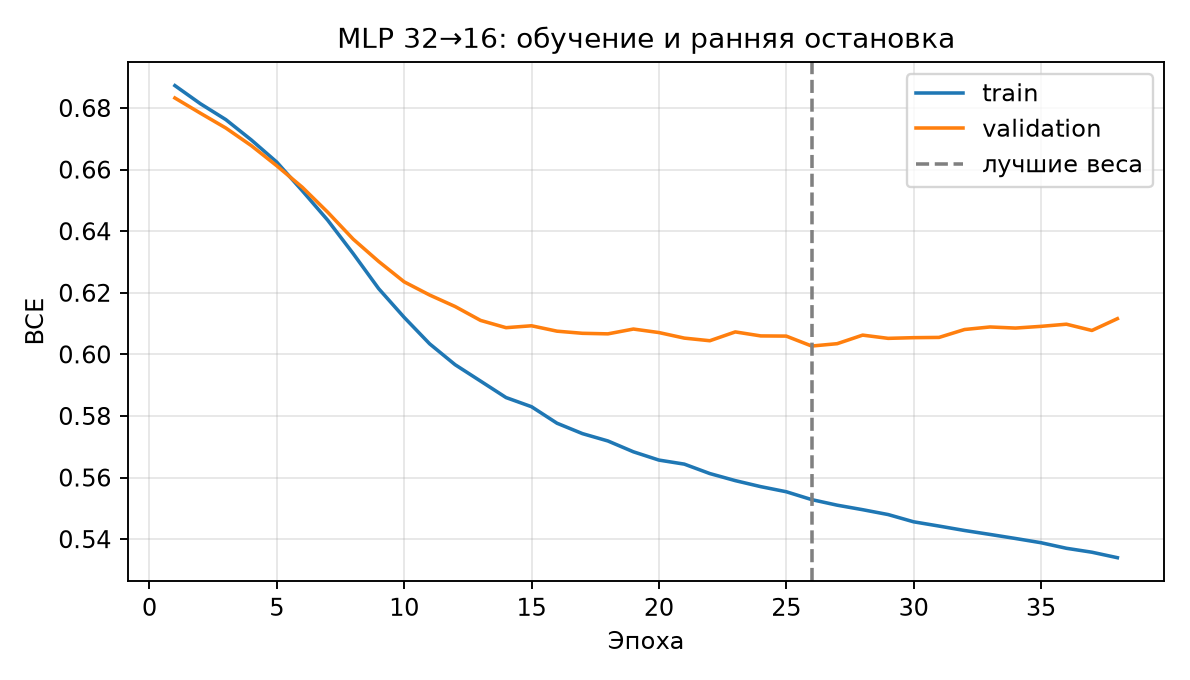

In [6]:
def fit_mlp(hidden=(32,16),batch_size=32,seed=42,max_epochs=120,patience=12):
    torch.manual_seed(seed)
    net=DeliveryMLP(Xtr.shape[1],hidden).to(device)
    loss_fn=nn.BCEWithLogitsLoss()
    opt=torch.optim.Adam(net.parameters(),lr=.001)
    loader=DataLoader(TensorDataset(torch.from_numpy(Xtr),torch.from_numpy(ytr)),batch_size=batch_size,
                      shuffle=True,generator=torch.Generator().manual_seed(seed))
    vx=torch.from_numpy(Xva).to(device);vy=torch.from_numpy(yva).to(device)
    history=[];best=float('inf');best_epoch=0;best_state=None;bad=0
    start=time.perf_counter()
    for epoch in range(1,max_epochs+1):
        net.train();total=0.0
        for xb,yb in loader:
            opt.zero_grad(set_to_none=True)
            logits=net(xb.to(device))
            loss=loss_fn(logits,yb.to(device))
            loss.backward();opt.step()
            total+=loss.item()*len(xb)
        net.eval()
        with torch.no_grad():vl=loss_fn(net(vx),vy).item()
        tl=total/len(Xtr)
        history.append((epoch,tl,vl))
        if vl<best-1e-4:
            best=vl;best_epoch=epoch;best_state=deepcopy(net.state_dict());bad=0
        else:bad+=1
        if bad>=patience:break
    duration=time.perf_counter()-start
    assert best_state is not None
    net.load_state_dict(best_state);net.eval()
    return net,pd.DataFrame(history,columns=['epoch','train_BCE','validation_BCE']),best_epoch,duration

model,hist,best_epoch,duration=fit_mlp()
print('Эпох:',len(hist),'лучшая эпоха:',best_epoch,'validation BCE:',hist.validation_BCE.min(),'время, с:',round(duration,2))
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(hist.epoch,hist.train_BCE,label='train');ax.plot(hist.epoch,hist.validation_BCE,label='validation')
ax.axvline(best_epoch,color='gray',linestyle='--',label='лучшие веса')
ax.set(xlabel='Эпоха',ylabel='BCE',title='MLP 32→16: обучение и ранняя остановка')
ax.grid(alpha=.3);ax.legend();fig.tight_layout();fig.savefig('20_learning.png',dpi=170);plt.close(fig)
display(Image(filename='20_learning.png'))

## 6. Сравнение с baseline на validation, финальная проверка test (69–82 мин)
Сравнивать модели можно только на **одном разбиении и одних входных данных**. Сначала сравните на validation. В рамках упражнения архитектура и порог 0,5 фиксированы до test; никаких новых настроек после тестирования.

In [7]:
def nn_probability(net,x):
    net.eval()
    with torch.no_grad():return torch.sigmoid(net(torch.from_numpy(x).to(device))).cpu().numpy().ravel()
def score_row(title,y,p,thr=.5):
    pred=(p>=thr).astype(int)
    return {'model':title,'N':len(y),'accuracy':accuracy_score(y,pred),
            'F1':f1_score(y,pred,zero_division=0),
            'AP':average_precision_score(y,p) if len(np.unique(y))==2 else np.nan,
            'BCE':log_loss(y,np.clip(p,1e-7,1-1e-7),labels=[0,1])}
prior=DummyClassifier(strategy='prior').fit(Xtr,ytr.ravel())
linear=LogisticRegression(max_iter=1000,random_state=SEED).fit(Xtr,ytr.ravel())
models=[('Dummy',prior),('LogReg',linear)]
valid_rows=[]
for name,clf in models:
    valid_rows.append(score_row(name,yva.ravel(),clf.predict_proba(Xva)[:,list(clf.classes_).index(1)]))
valid_rows.append(score_row('MLP 32→16',yva.ravel(),nn_probability(model,Xva)))
valid_scores=pd.DataFrame(valid_rows)
display(valid_scores.round(4))
print('До просмотра test зафиксированы: три модели, архитектура 32→16, порог 0,5, seed 42, правило early stopping.')

,model,N,accuracy,F1,AP,BCE
0,Dummy,119,0.5546,0.0000,0.4454,0.6872
1,LogReg,119,0.6387,0.5981,0.7333,0.5992
2,MLP 32→16,119,0.6471,0.6111,0.7260,0.6027


До просмотра test зафиксированы: три модели, архитектура 32→16, порог 0,5, seed 42, правило early stopping.


,configuration,parameters,epochs,best_epoch,seconds,validation_F1,min_validation_BCE
0,"32→16, batch 32",929,38,26,0.2743,0.6111,0.6027
1,"16, batch 32",209,41,29,0.2494,0.5918,0.5946
2,"32→16, batch 16",929,25,13,0.3030,0.6226,0.6073


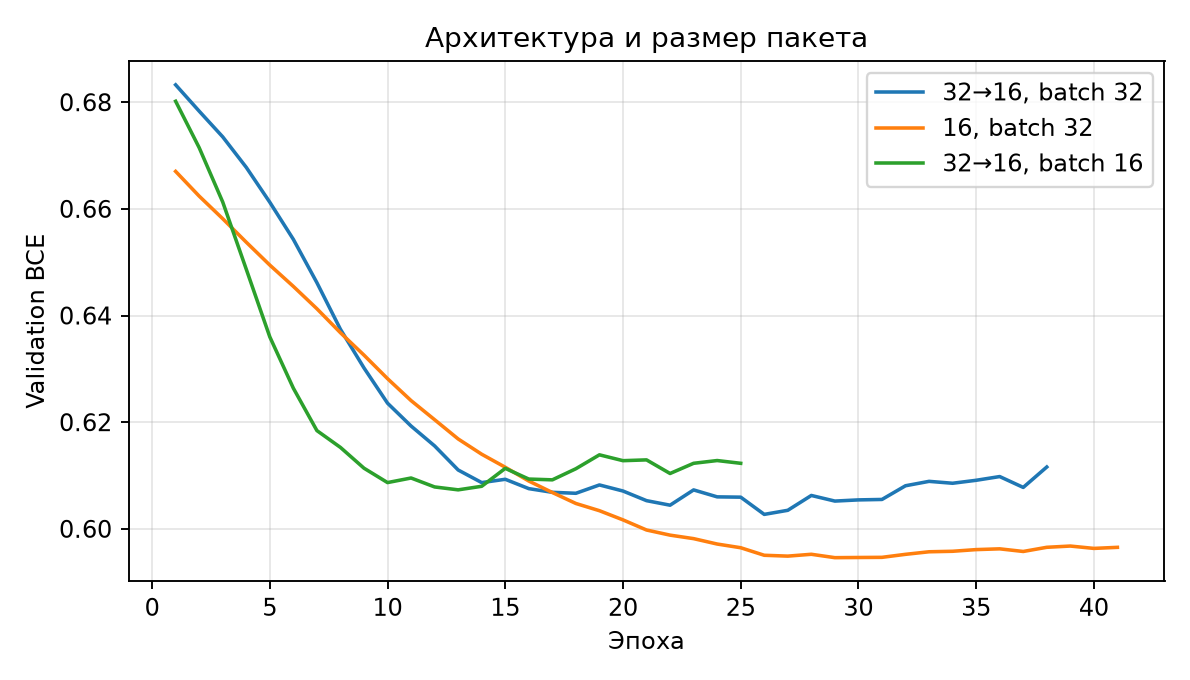

,model,N,accuracy,F1,AP,BCE
0,Dummy,121,0.4545,0.0000,0.5455,0.7074
1,LogReg,121,0.6612,0.6612,0.7528,0.6297
2,MLP 32→16,121,0.6612,0.6555,0.7507,0.6340


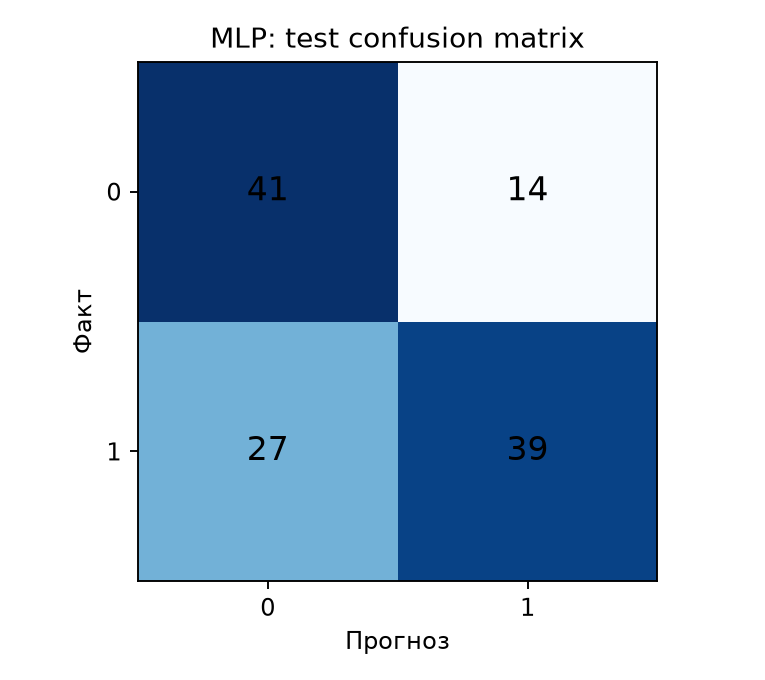

Test просмотрен однократно; после оценки модель, порог и настройки не меняются.


In [8]:
# Сначала самостоятельные сравнения только на validation: результаты test здесь ещё не доступны.
small_model,small_hist,small_best,small_duration=fit_mlp(hidden=(16,),seed=SEED)
batch_model,batch_hist,batch_best,batch_duration=fit_mlp(hidden=(32,16),batch_size=16,seed=SEED)
small_params=(Xtr.shape[1]+1)*16+(16+1)
compare=pd.DataFrame([
 ('32→16, batch 32',expected_params,len(hist),best_epoch,duration,
  score_row('x',yva.ravel(),nn_probability(model,Xva))['F1'],hist.validation_BCE.min()),
 ('16, batch 32',small_params,len(small_hist),small_best,small_duration,
  score_row('x',yva.ravel(),nn_probability(small_model,Xva))['F1'],small_hist.validation_BCE.min()),
 ('32→16, batch 16',expected_params,len(batch_hist),batch_best,batch_duration,
  score_row('x',yva.ravel(),nn_probability(batch_model,Xva))['F1'],batch_hist.validation_BCE.min())],
 columns=['configuration','parameters','epochs','best_epoch','seconds','validation_F1','min_validation_BCE'])
display(compare.round(4))
fig,ax=plt.subplots(figsize=(7,4))
for label,h in [('32→16, batch 32',hist),('16, batch 32',small_hist),('32→16, batch 16',batch_hist)]:
    ax.plot(h.epoch,h.validation_BCE,label=label)
ax.set(xlabel='Эпоха',ylabel='Validation BCE',title='Архитектура и размер пакета')
ax.grid(alpha=.3);ax.legend();fig.tight_layout();fig.savefig('20_validation_comparison.png',dpi=170);plt.close(fig)
display(Image(filename='20_validation_comparison.png'))

# Протокол финального test был зафиксирован выше; дополнительные варианты в test не оцениваем.
Xte=np.asarray(prep.transform(te[num_cols+cat_cols]),dtype=np.float32)
yte=te.late.to_numpy(dtype=np.float32).reshape(-1,1)
assert Xte.dtype==np.float32 and np.isfinite(Xte).all()
test_rows=[]
for name,clf in models:
    test_rows.append(score_row(name,yte.ravel(),clf.predict_proba(Xte)[:,list(clf.classes_).index(1)]))
pte=nn_probability(model,Xte)
test_rows.append(score_row('MLP 32→16',yte.ravel(),pte))
test_scores=pd.DataFrame(test_rows)
display(test_scores.round(4))
cm=confusion_matrix(yte.ravel(),(pte>=.5).astype(int),labels=[0,1])
fig,ax=plt.subplots(figsize=(4.5,4))
ax.imshow(cm,cmap='Blues');ax.set_xticks([0,1]);ax.set_yticks([0,1])
ax.set(xlabel='Прогноз',ylabel='Факт',title='MLP: test confusion matrix')
for (i,j),v in np.ndenumerate(cm):ax.text(j,i,str(v),ha='center',va='center',fontsize=14)
fig.tight_layout();fig.savefig('20_test_confusion.png',dpi=170);plt.close(fig)
display(Image(filename='20_test_confusion.png'))
assert cm.sum()==len(yte)
print('Test просмотрен однократно; после оценки модель, порог и настройки не меняются.')

## 7. Сохранение результатов и самостоятельные задания (82–90 мин)
Сохраните веса MLP и параметры подготовки, чтобы эксперимент можно было повторить. Сведения о версиях и входных полях — обязательная часть отчёта.

In [9]:
folder=Path('results_20');folder.mkdir(exist_ok=True)
torch.save(model.state_dict(),folder/'mlp_state_dict.pt')
joblib.dump(prep,folder/'preprocessor.joblib')
hist.to_csv(folder/'history.csv',index=False)
valid_scores.to_csv(folder/'validation_metrics.csv',index=False)
test_scores.to_csv(folder/'test_metrics.csv',index=False)
compare.to_csv(folder/'validation_experiments.csv',index=False)
audit_table.to_csv(folder/'cleaning_audit.csv',index=False)
split_table.to_csv(folder/'split_summary.csv',index=False)
pd.DataFrame(cm,index=['actual_0','actual_1'],columns=['pred_0','pred_1']).to_csv(folder/'test_confusion.csv')
meta={'seed':SEED,'source':dataset.name,'features':num_cols+cat_cols,'input_dim':Xtr.shape[1],
      'architecture':[Xtr.shape[1],32,16,1],'threshold':0.5,'batch_size':32,'patience':12,
      'best_epoch':best_epoch,'torch':torch.__version__,'numpy':np.__version__,
      'pandas':pd.__version__,'sklearn':sklearn.__version__}
(folder/'metadata.json').write_text(json.dumps(meta,ensure_ascii=False,indent=2),encoding='utf-8')
restored=DeliveryMLP(Xtr.shape[1],(32,16))
restored.load_state_dict(torch.load(folder/'mlp_state_dict.pt',map_location='cpu',weights_only=True))
restored_prep=joblib.load(folder/'preprocessor.joblib')
assert np.allclose(nn_probability(model,Xva),nn_probability(restored,Xva))
assert np.allclose(Xva,restored_prep.transform(va[num_cols+cat_cols]).astype(np.float32))
print('Сохранены:',sorted(q.name for q in folder.iterdir()))
print('Загрузка весов и препроцессора проверена на validation.')

Сохранены: ['cleaning_audit.csv', 'history.csv', 'metadata.json', 'mlp_state_dict.pt', 'preprocessor.joblib', 'split_summary.csv', 'test_confusion.csv', 'test_metrics.csv', 'validation_experiments.csv', 'validation_metrics.csv']
Загрузка весов и препроцессора проверена на validation.


**Самостоятельно:** (1) объясните размерность `Xtr` после one-hot; (2) сравните минимум две архитектуры **только по validation** — эксперимент организуйте на отдельных запусках до финального test; (3) объясните значение `model.train()`, `model.eval()`, `zero_grad()` и `no_grad()`; (4) сравните качество нейросети с LogisticRegression и Dummy, указав ограничения малого синтетического набора; (5) приведите две кривые loss и confusion matrix.

**Сдать:** `20_student.ipynb`, `Группа_Фамилия_З20_Отчет.docx` (2–4 страницы), папку `results_20` по требованию преподавателя.

**Оценивание (10 баллов):** корректная предобработка и разбиение — 2; архитектура и автодифференцирование — 2; цикл обучения/валидация — 3; сравнение и матрица ошибок — 2; воспроизводимость/выводы — 1.

**Контрольные вопросы:** Почему `BCEWithLogitsLoss` не требует `Sigmoid()` внутри модели? Чем validation отличается от test? Что такое mini-batch? Почему исходный ID нельзя подавать в модель? Когда имеет смысл выбрать логистическую регрессию вместо нейросети?

### Ответы на вопросы ноутбука

**Раздел 1. Почему `loss.backward()` получает все градиенты?** Tensor с `requires_grad=True` участвует в графе операций. Для $z=xW+b$ производная по каждому весу равна соответствующему входу: $\partial z/\partial w_i=x_i$. В опыте $z=0{,}5$ и $\nabla_w z=(2,1)$, что совпало с `autograd`; для сложной сети производные проходят по графу по цепному правилу.

**Размерность `Xtr` после one-hot.** Получено 11 входных столбцов: 4 числовых (`distance_km`, `queue_size`, `promised_minutes`, `order_hour`) и 7 индикаторов для категорий `zone` и `weather`. Признак `courier_load` в исходном файле отсутствует, поэтому не использовался. Код выводит точные имена столбцов после `ColumnTransformer`.

**Сравнение архитектур на validation.** Сеть 11→32→16→1 содержит 929 обучаемых параметров, сеть 11→16→1 — 209, разница 720. На одинаковом временном разбиении и при seed 42 минимум validation BCE составил 0,6027 и 0,5946 соответственно; F1 при пороге 0,5 — 0,6111 и 0,5918. Более компактная сеть лучше по BCE, но уступает по F1; качество зависит от выбранной метрики. Дополнительная сеть оценивалась только на validation и не участвовала в финальной проверке test.

**Размер mini-batch.** Для основной архитектуры batch 32 дал 38 эпох до остановки, лучшую эпоху 26 и минимум validation BCE 0,6027. Batch 16 дал 25 эпох до остановки, лучшую эпоху 13 и BCE 0,6073; на данном запуске F1 составил 0,6226 против 0,6111. Меньший пакет делает больше обновлений за эпоху, поэтому сравнение только по номеру эпохи не равно сравнению числа шагов оптимизатора. В данном запуске оба варианта заняли около 0,3 с; точные значения выведены в таблице. Эти короткие измерения зависят от машины и нагрузки, а один seed не позволяет делать общий вывод о скорости или качестве.

**Режимы PyTorch.** `model.train()` включает обучающий режим слоёв, `model.eval()` — режим оценки. В этой сети ReLU и Linear ведут себя одинаково в обоих режимах, но вызовы важны для общего протокола, особенно при Dropout или BatchNorm. `optimizer.zero_grad()` очищает накопленные градиенты перед очередным пакетом; `torch.no_grad()` запрещает построение графа на validation и test, снижая расход памяти и не допуская ненужного обратного прохода.

**Сравнение моделей.** На validation Dummy получил Accuracy 0,5546, F1 0; LogReg — 0,6387 и 0,5981; MLP — 0,6471 и 0,6111. На однократно открытом test LogReg и MLP имеют одинаковую Accuracy 0,6612, а F1 у LogReg немного выше (0,6612 против 0,6555). Поэтому небольшой выигрыш MLP на validation не доказывает её превосходство в новых данных. Набор синтетический, содержит 598 очищенных заказов и охватывает короткий период; итог может не переноситься на реальные условия.

**Когда лучше LogisticRegression?** При малом объёме данных её меньшая сложность снижает риск переобучения; при требовании интерпретировать влияние признаков её коэффициенты проще объяснять; при ограничениях на вычисления и поддержку её быстрее обучать и сопровождать. Здесь она также не уступила MLP по Accuracy на test.

**Расхождение train и validation BCE.** Train BCE постепенно снижается до 0,5340 к 38-й эпохе, а validation BCE достигает минимума 0,6027 на 26-й, после чего колеблется и растёт до 0,6116. Такое расхождение совместимо с началом переобучения или временным сдвигом распределения. Ранняя остановка восстановила веса 26-й эпохи, поэтому финальная оценка использует лучший по validation вариант.

**Графики и матрица.** Кривая train/validation BCE и график сравнения настроек приведены выше; матрица ошибок для MLP на test содержит TN=41, FP=14, FN=27, TP=39. Порог 0,5 был зафиксирован до test. Препроцессор обучен только на train; исходный `orders_dirty.csv` не менялся.